# 1 - The operator, the solver, and Jiang's formula

$$D^{\alpha} y(t) = -\lambda\, y(t) + f(t), \qquad y(0)=0, \qquad 0<\alpha<1$$

with the **Caputo** derivative $D^{\alpha}y(t)=\frac{1}{\Gamma(1-\alpha)}\int_0^t (t-s)^{-\alpha}y'(s)\,ds$.

Three facts organise the whole project.

**1. The map $f\mapsto y$ is a causal convolution.** With $y(0)=0$,
$$y(t)=\int_0^t K(t-r) f(r)\,dr,\qquad K(t)=t^{\alpha-1}E_{\alpha,\alpha}(-\lambda t^{\alpha}),\qquad \hat K(p)=\frac{1}{p^{\alpha}+\lambda}.$$

**2. $K$ is a continuous superposition of exponentials.** $\hat K$ is a Stieltjes
function, so $K$ is completely monotone and
$$K(t)=\int_0^{\infty} e^{-st}\mu(s)\,ds,\qquad
\mu(s)=\frac{1}{\pi}\,\frac{s^{\alpha}\sin(\pi\alpha)}{s^{2\alpha}+2\lambda s^{\alpha}\cos(\pi\alpha)+\lambda^{2}}.$$
The two limits of $\mu$ give the two power laws
$K(t)\sim t^{\alpha-1}/\Gamma(\alpha)$ for $t\to 0$ and
$K(t)\sim \frac{\alpha}{\Gamma(1-\alpha)\lambda^{2}}t^{-1-\alpha}$ for $t\to\infty$:
**algebraic memory, never exponential**.

**3. Discretising that integral is exactly what Jiang's formula does, and exactly
what a diagonal SSM does.** Each node $s_j$ is one mode $h_j'=-s_jh_j+f$,
i.e. one SSM state with pole $A_j=e^{-s_j\tau}$. That is the bridge between the
numerical analysis and the neural network, and the subject of notebook 2.

The ground truth here is the **L1 scheme** on a uniform grid:
$$D^{\alpha}y(t_n)\approx\frac{\tau^{-\alpha}}{\Gamma(2-\alpha)}\sum_{k=0}^{n-1}b_k\,(y_{n-k}-y_{n-k-1}),\qquad b_k=(k+1)^{1-\alpha}-k^{1-\alpha}.$$

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import exact, jiang
from src.config import TAU, LAM, ALPHAS_TRAIN, L_TRAIN, L_LONG, N_STATES, RESULTS, DATA
from src.bands import T_TRAIN, T_LONG, jiang_nodes
from src.l1 import l1_solve, discrete_kernel
from src.style import use_style, SLOT, INK, INK2, INK3, REFERENCE, despine
use_style()
print(f"tau={TAU}  lambda={LAM}  train horizon T={T_TRAIN}  long horizon T={T_LONG}")

tau=0.01  lambda=1.0  train horizon T=10.0  long horizon T=100.0


## 1.1 Is the solver right?

Four independent checks (the full set is `python -m src.validate`).
`exact.py` never uses the L1 scheme, so agreement is meaningful.

In [2]:
# (i) the spectral density really is the inverse Laplace transform of 1/(p^a+lam)
for a in (0.2, 0.5, 0.9):
    print(f"alpha={a}:  max rel err of int mu(s)/(p+s) ds vs 1/(p^a+lam) = "
          f"{exact.check_spectral_density(a, LAM):.2e}")

alpha=0.2:  max rel err of int mu(s)/(p+s) ds vs 1/(p^a+lam) = 1.98e-16
alpha=0.5:  max rel err of int mu(s)/(p+s) ds vs 1/(p^a+lam) = 3.60e-16
alpha=0.9:  max rel err of int mu(s)/(p+s) ds vs 1/(p^a+lam) = 2.97e-16


In [3]:
# (ii) L1 vs the exact step response (f == 1), and the observed order in tau
alpha, T = 0.5, 1.0
ref = float(exact.step_response(T, alpha, LAM)[0])
errs = []
for N in (100, 200, 400, 800, 1600, 3200):
    y = l1_solve(np.ones(N), alpha, LAM, T / N)
    errs.append(abs(y[-1] - ref) / abs(ref))
    print(f"N={N:5d}  tau={T/N:.5f}  rel err={errs[-1]:.3e}")
print("observed orders:", [f"{np.log2(errs[i]/errs[i+1]):.2f}" for i in range(len(errs)-1)])

N=  100  tau=0.01000  rel err=1.244e-03
N=  200  tau=0.00500  rel err=6.143e-04
N=  400  tau=0.00250  rel err=3.045e-04
N=  800  tau=0.00125  rel err=1.513e-04
N= 1600  tau=0.00063  rel err=7.535e-05
N= 3200  tau=0.00031  rel err=3.756e-05
observed orders: ['1.02', '1.01', '1.01', '1.01', '1.00']


In [4]:
# (iii) with y(0)=0 the scheme is exactly LTI, so it equals a convolution with
#       its own impulse response -- this is what makes data generation O(L log L)
from src.l1 import l1_solve_fft
f = np.random.default_rng(0).standard_normal((4, 3000))
y1, y2 = l1_solve(f, 0.35, LAM, TAU), l1_solve_fft(f, 0.35, LAM, TAU)
print("max rel diff recursion vs FFT:", np.abs(y1 - y2).max() / np.abs(y1).max())

max rel diff recursion vs FFT: 5.034422465103992e-16


## 1.2 The memory kernel

Circles are the L1 scheme's own impulse response $g[n]$, lines are the exact
$K(t)$. They agree everywhere except in the first few steps, where $K$ has an
integrable singularity that a one-step scheme cannot resolve (+70% at $t=\tau$,
decaying to $6\times10^{-4}$ by $t=24$). **The L1 kernel is the ground truth the
models are trained against**, so this is a property of the target, not an error.

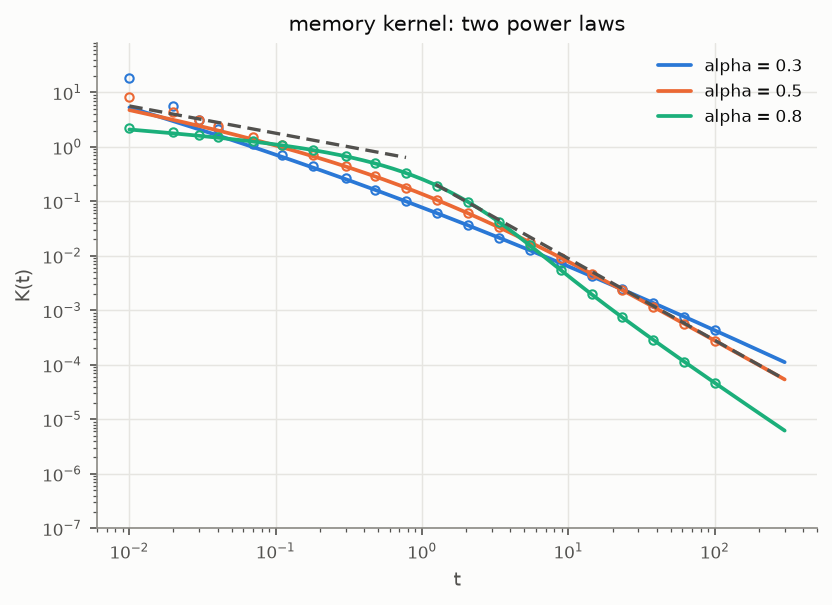

In [5]:
t = np.exp(np.linspace(np.log(TAU), np.log(300.0), 200))
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for i, al in enumerate((0.3, 0.5, 0.8)):
    ax.loglog(t, exact.kernel(t, al, LAM), color=SLOT[i], label=f"alpha = {al}")
    g = discrete_kernel(al, LAM, TAU, L_LONG)
    n = np.unique(np.round(np.exp(np.linspace(0, np.log(L_LONG), 20))).astype(int))
    ax.loglog(n * TAU, g[n - 1], ls="none", marker="o", ms=4, mfc="none", mec=SLOT[i])
sm, lg = exact.kernel_asymptotes(t, 0.5, LAM)
ax.loglog(t[t < 0.8], sm[t < 0.8], **REFERENCE); ax.loglog(t[t > 1.2], lg[t > 1.2], **REFERENCE)
ax.set(xlabel="t", ylabel="K(t)", ylim=(1e-7, 80), title="memory kernel: two power laws")
ax.legend(); despine(ax); plt.show()

## 1.3 Jiang's formula

For $0<\beta<1$, $\;t^{-\beta}=\frac{1}{\Gamma(\beta)}\int_0^\infty e^{-st}s^{\beta-1}ds$.
Jiang et al. (CiCP 2017) discretise that integral with a composite Gauss rule:
Gauss-Jacobi with weight $s^{\beta-1}$ on $[0,s_{\min}]$ (absorbing the
singularity exactly), Gauss-Legendre on geometric panels up to $s_{\max}$, and
truncation beyond. The result is
$$t^{-\beta}\approx\sum_{j=1}^{N_{\exp}} w_j e^{-s_jt},\qquad t\in[\tau,T],$$
with $N_{\exp}=O(\log\frac1\varepsilon\,\log\frac{T}{\tau})$ - logarithmic in the
dynamic range, which is why 64 modes cover four decades.

In [6]:
beta = 0.5
for eps in (1e-2, 1e-4, 1e-6, 1e-8, 1e-10):
    s, w = jiang.soe_power(beta, TAU, T_LONG, eps=eps, n_jacobi=16, n_leg=8)
    err, _, _ = jiang.soe_power_error(beta, s, w, TAU, T_LONG)
    print(f"eps={eps:.0e}   N_exp={len(s):4d}   achieved max rel err={err:.2e}"
          f"   s in [{s.min():.2e}, {s.max():.2e}]")

eps=1e-02   N_exp= 152   achieved max rel err=8.93e-03   s in [1.17e-05, 3.42e+02]
eps=1e-04   N_exp= 160   achieved max rel err=9.44e-05   s in [1.17e-05, 7.60e+02]
eps=1e-06   N_exp= 160   achieved max rel err=9.63e-07   s in [1.17e-05, 1.19e+03]
eps=1e-08   N_exp= 168   achieved max rel err=9.72e-09   s in [1.17e-05, 1.64e+03]
eps=1e-10   N_exp= 168   achieved max rel err=9.84e-11   s in [1.17e-05, 2.08e+03]


In [7]:
# the node set actually used by the models, and how well it fits each kernel
s_nodes, info = jiang_nodes(T_LONG, N_STATES)
print(f"{len(s_nodes)} nodes, s in [{s_nodes.min():.3e}, {s_nodes.max():.3e}], rule={info}")
print(f"nodes per decade: {len(s_nodes)/np.log10(s_nodes.max()/s_nodes.min()):.1f}\n")
for al in (0.2, 0.5, 0.9):
    g = discrete_kernel(al, LAM, TAU, L_LONG)
    c = jiang.fit_weights_to_kernel(s_nodes, g, TAU)
    k = jiang.soe_design(s_nodes, TAU, np.arange(1, L_LONG + 1)) @ c
    rel = np.abs(k - TAU * g) / (TAU * g)
    print(f"alpha={al}:  64 fixed exponentials fit the L1 kernel to "
          f"max {rel.max():.1e} / median {np.median(rel):.1e} relative")

64 nodes, s in [1.507e-04, 1.165e+03], rule={'err': 1.1522873634505287e-06, 'eps': 1e-06, 'ratio': 8.0, 'n_leg': 10, 'n_jacobi': 4, 'n_exp': 64, 'T': 100.0, 'n_max': 64, 'alpha_ref': 0.55}
nodes per decade: 9.3

alpha=0.2:  64 fixed exponentials fit the L1 kernel to max 2.0e-08 / median 1.1e-09 relative


alpha=0.5:  64 fixed exponentials fit the L1 kernel to max 6.7e-10 / median 1.9e-10 relative
alpha=0.9:  64 fixed exponentials fit the L1 kernel to max 1.3e-08 / median 5.1e-09 relative


One shared grid works for every $\alpha$ (the $\alpha$-dependence of the node
set enters only through the few Gauss-Jacobi nodes). That is why the
fixed-exponent model can use a single frozen bank of 64 poles and learn only the
readout $c_j(\alpha)$.

## 1.4 The dataset

`python -m src.datagen` writes the `.npz` files. $\tau$ is **fixed**, so a longer
sequence is a longer physical horizon and a longer memory - that is what makes
"train short / test long" a statement about the kernel rather than a change of
units. Eight forcing families with length-independent statistics, $f$ normalised
to unit RMS.

{'tau': 0.01, 'lam': 1.0, 'L': 1000, 'n': 32, 'scheme': 'L1 (Caputo), y0=0'}
alphas: [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
forcing families: ['white', 'ou', 'smooth', 'steps', 'bursts', 'chirp', 'ramp_noise', 'mix']


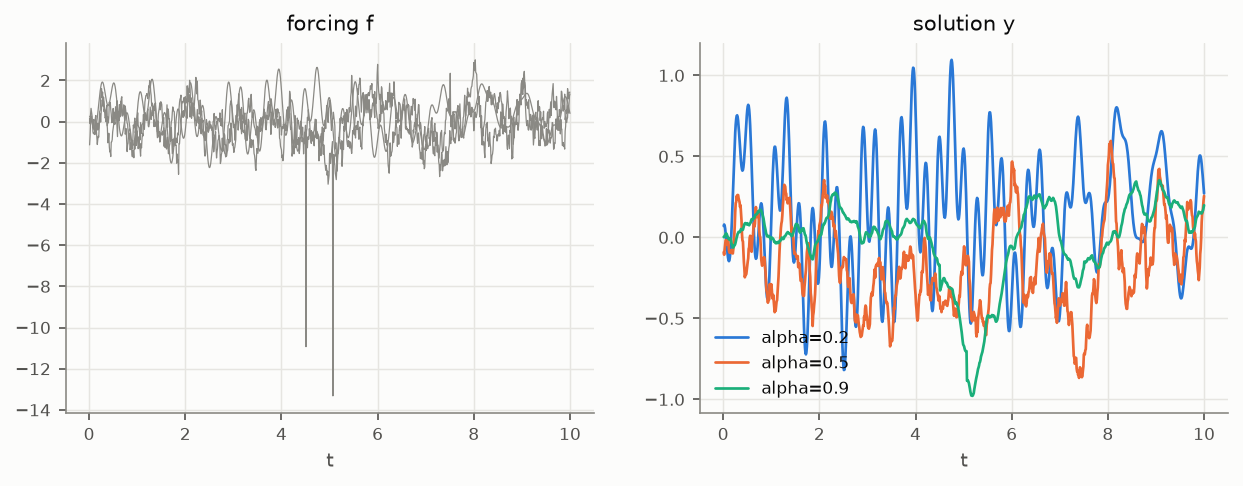

In [8]:
d = np.load(os.path.join(DATA, "demo_small.npz"), allow_pickle=True)
meta = json.loads(str(d["meta"]))
print({k: meta[k] for k in ("tau", "lam", "L", "n", "scheme")})
print("alphas:", meta["alphas"])
print("forcing families:", meta["kinds"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
t = np.arange(1, d["f"].shape[1] + 1) * TAU
for j, al in enumerate((0.2, 0.5, 0.9)):
    i = int(np.argmin(np.abs(d["alpha"] - al)))
    ax[0].plot(t, d["f"][i], color=INK3, lw=0.6)
    ax[1].plot(t, d["y"][i], color=SLOT[j], lw=1.3, label=f"alpha={al}")
ax[0].set(xlabel="t", title="forcing f"); ax[1].set(xlabel="t", title="solution y")
ax[1].legend(); [despine(a) for a in ax]; plt.show()